In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, optimizers
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from scikeras.wrappers import KerasClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time

np.random.seed(42)
tf.random.set_seed(42)


In [2]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()
class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print("train shape:", x_train.shape, y_train.shape)
print("test shape :", x_test.shape, y_test.shape)
print("pixel min  :", x_train.min(), "max:", x_train.max())
print("classes    :", len(class_names))


train shape: (60000, 28, 28) (60000,)
test shape : (10000, 28, 28) (10000,)
pixel min  : 0 max: 255
classes    : 10


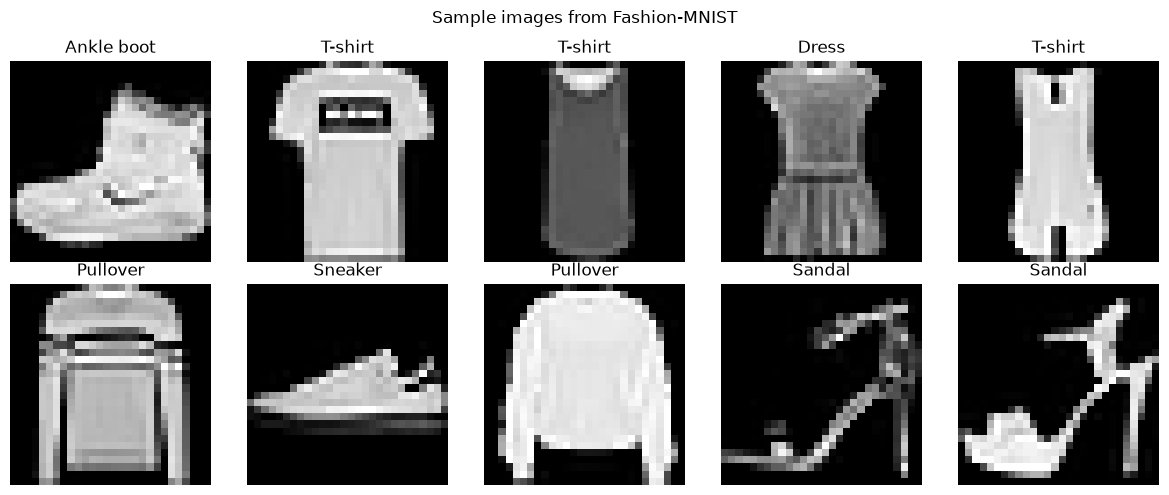

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(class_names[y_train[i]])
    ax.axis('off')
plt.suptitle("Sample images from Fashion-MNIST")
plt.tight_layout()
plt.savefig("plot_01_sample_images.png", dpi=110, bbox_inches='tight')
plt.show()


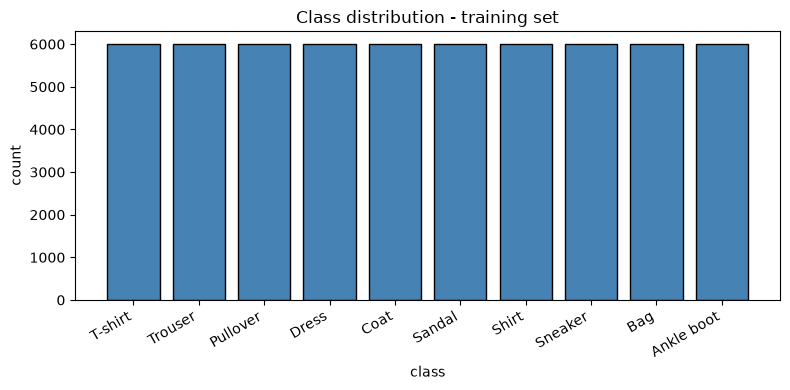

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
counts, _ = np.histogram(y_train, bins=np.arange(11) - 0.5)
ax.bar(class_names, counts, color='steelblue', edgecolor='black')
ax.set_title("Class distribution - training set")
ax.set_xlabel("class")
ax.set_ylabel("count")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig("plot_02_class_distribution.png", dpi=110, bbox_inches='tight')
plt.show()


In [5]:
x_train_flat = x_train.reshape(x_train.shape[0], 784).astype('float32') / 255.0
x_test_flat = x_test.reshape(x_test.shape[0], 784).astype('float32') / 255.0
y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)
print("before:", x_train.shape, y_train.shape)
print("after :", x_train_flat.shape, y_train_oh.shape)
print("x range:", x_train_flat.min(), "to", x_train_flat.max())


before: (60000, 28, 28) (60000,)
after : (60000, 784) (60000, 10)
x range: 0.0 to 1.0


In [6]:
baseline_model = models.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
baseline_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
t0 = time.time()
baseline_history = baseline_model.fit(
    x_train_flat, y_train_oh,
    validation_split=0.1,
    epochs=20,
    batch_size=32,
    verbose=2
)
baseline_train_time = time.time() - t0
print("baseline training time: %.2f s" % baseline_train_time)


Epoch 1/20


1688/1688 - 3s - 1ms/step - accuracy: 0.8235 - loss: 0.4978 - val_accuracy: 0.8517 - val_loss: 0.3919


Epoch 2/20


1688/1688 - 2s - 1ms/step - accuracy: 0.8636 - loss: 0.3711 - val_accuracy: 0.8623 - val_loss: 0.3703


Epoch 3/20


1688/1688 - 2s - 1ms/step - accuracy: 0.8764 - loss: 0.3349 - val_accuracy: 0.8632 - val_loss: 0.3674


... (31 outputs left out)

1688/1688 - 2s - 1ms/step - accuracy: 0.9353 - loss: 0.1710 - val_accuracy: 0.8813 - val_loss: 0.4509


Epoch 20/20


1688/1688 - 2s - 1ms/step - accuracy: 0.9381 - loss: 0.1649 - val_accuracy: 0.8790 - val_loss: 0.4854


baseline training time: 40.71 s


In [8]:
def eval_model(m, name):
    probs = m.predict(x_test_flat, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    print("=== %s ===" % name)
    print("accuracy : %.4f" % acc)
    print("precision: %.4f" % prec)
    print("recall   : %.4f" % rec)
    print("f1       : %.4f" % f1)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
    return acc, prec, rec, f1, y_pred

baseline_acc, baseline_prec, baseline_rec, baseline_f1, y_pred_base = eval_model(baseline_model, "Baseline")


=== Baseline ===
accuracy : 0.8713
precision: 0.8745
recall   : 0.8713
f1       : 0.8693
              precision    recall  f1-score   support

     T-shirt     0.7143    0.8950    0.7945      1000
     Trouser     0.9948    0.9640    0.9792      1000
    Pullover     0.7779    0.7740    0.7759      1000
       Dress     0.8566    0.8900    0.8730      1000
        Coat     0.7730    0.8410    0.8056      1000
      Sandal     0.9281    0.9680    0.9476      1000
       Shirt     0.7912    0.5420    0.6433      1000
     Sneaker     0.9561    0.9370    0.9465      1000
         Bag     0.9835    0.9520    0.9675      1000
  Ankle boot     0.9694    0.9500    0.9596      1000

    accuracy                         0.8713     10000
   macro avg     0.8745    0.8713    0.8693     10000
weighted avg     0.8745    0.8713    0.8693     10000



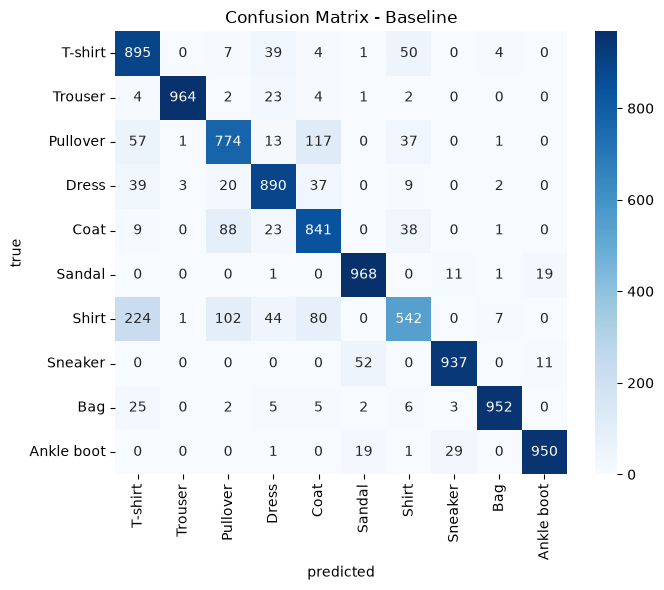

In [9]:
cm = confusion_matrix(y_test, y_pred_base)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion Matrix - Baseline")
plt.tight_layout()
plt.savefig("plot_07_confusion_matrix_baseline.png", dpi=110, bbox_inches='tight')
plt.show()


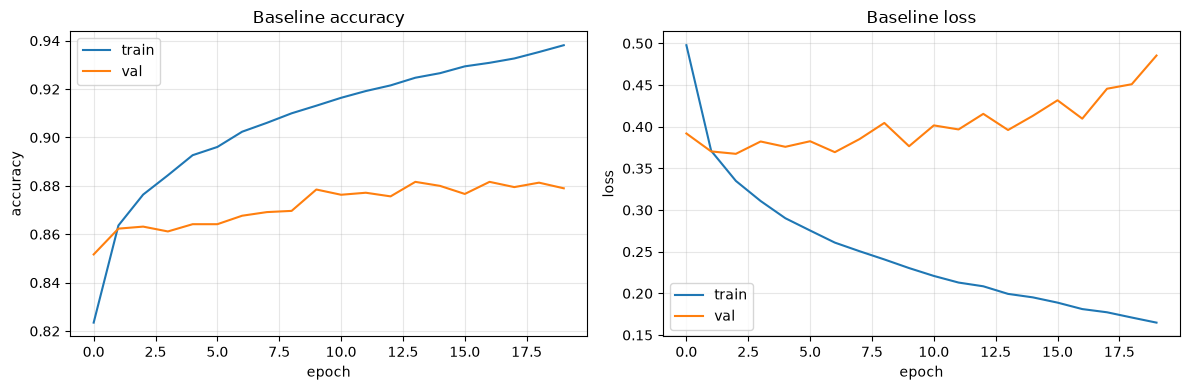

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(baseline_history.history['accuracy'], label='train')
axes[0].plot(baseline_history.history['val_accuracy'], label='val')
axes[0].set_title("Baseline accuracy")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(baseline_history.history['loss'], label='train')
axes[1].plot(baseline_history.history['val_loss'], label='val')
axes[1].set_title("Baseline loss")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_03_04_05_06_baseline_curves.png", dpi=110, bbox_inches='tight')
plt.show()


In [11]:
def build_fn(hidden_layers=2, hidden_neurons=128, learning_rate=0.001, optimizer='adam', activation='relu', dropout=0.0):
    m = models.Sequential()
    m.add(layers.Input(shape=(784,)))
    for _ in range(hidden_layers):
        m.add(layers.Dense(hidden_neurons, activation=activation))
        if dropout and dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation='softmax'))
    if optimizer == 'sgd':
        opt = optimizers.SGD(learning_rate=learning_rate)
    elif optimizer == 'rmsprop':
        opt = optimizers.RMSprop(learning_rate=learning_rate)
    else:
        opt = optimizers.Adam(learning_rate=learning_rate)
    m.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return m

param_distributions = {
    'model__hidden_layers': [1, 2, 3],
    'model__hidden_neurons': [32, 64, 128, 256],
    'model__learning_rate': [0.1, 0.01, 0.001],
    'batch_size': [16, 32, 64, 128],
    'epochs': [10, 20, 30],
    'model__optimizer': ['sgd', 'adam', 'rmsprop'],
    'model__activation': ['relu', 'tanh', 'sigmoid'],
    'model__dropout': [0.0, 0.2, 0.5]
}

clf = KerasClassifier(
    model=build_fn,
    verbose=0,
    model__hidden_layers=2,
    model__hidden_neurons=128,
    model__learning_rate=0.001,
    model__optimizer='adam',
    model__activation='relu',
    model__dropout=0.0
)


In [12]:
search_subset = 6000
rng = np.random.default_rng(42)
idx = rng.choice(x_train_flat.shape[0], size=search_subset, replace=False)
xs_search = x_train_flat[idx]
ys_search = y_train_oh[idx]

t0 = time.time()
search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=1,
    verbose=2
)
search_result = search.fit(xs_search, ys_search)
search_time = time.time() - t0
print("search time: %.2f s" % search_time)
print("best cv accuracy: %.4f" % search_result.best_score_)
print("best params:", search_result.best_params_)


Fitting 3 folds for each of 10 candidates, totalling 30 fits


[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   3.0s


[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   2.8s


[CV] END batch_size=64, epochs=20, model__activation=tanh, model__dropout=0.2, model__hidden_layers=1, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   2.9s


[CV] END batch_size=16, epochs=10, model__activation=sigmoid, model__dropout=0.2, model__hidden_layers=3, model__hidden_neurons=256, model__learning_rate=0.01, model__optimizer=rmsprop; total time=   5.4s


[CV] END batch_size=16, epochs=10, model__activation=sigmoid, model__dropout=0.2, model__hidden_layers=3, model__hidden_neurons=256, model__learning_rate=0.01, model__optimizer=rmsprop; total time=   5.2s


... (22 outputs left out)

[CV] END batch_size=32, epochs=30, model__activation=sigmoid, model__dropout=0.0, model__hidden_layers=2, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   8.4s


[CV] END batch_size=32, epochs=30, model__activation=sigmoid, model__dropout=0.0, model__hidden_layers=2, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   8.2s


[CV] END batch_size=32, epochs=30, model__activation=sigmoid, model__dropout=0.0, model__hidden_layers=2, model__hidden_neurons=256, model__learning_rate=0.001, model__optimizer=adam; total time=   8.5s


search time: 130.95 s
best cv accuracy: 0.8408
best params: {'model__optimizer': 'adam', 'model__learning_rate': 0.001, 'model__hidden_neurons': 32, 'model__hidden_layers': 1, 'model__dropout': 0.0, 'model__activation': 'tanh', 'epochs': 30, 'batch_size': 32}


In [13]:
results_df = pd.DataFrame(search_result.cv_results_)
results_df = results_df.sort_values('mean_test_score', ascending=False).head(10).reset_index(drop=True)
print(results_df[['mean_test_score', 'std_test_score', 'params']].to_string())


   mean_test_score  std_test_score                                                                                                                                                                                                         params
0         0.840833        0.006249        {'model__optimizer': 'adam', 'model__learning_rate': 0.001, 'model__hidden_neurons': 32, 'model__hidden_layers': 1, 'model__dropout': 0.0, 'model__activation': 'tanh', 'epochs': 30, 'batch_size': 32}
1         0.840167        0.005720    {'model__optimizer': 'rmsprop', 'model__learning_rate': 0.001, 'model__hidden_neurons': 128, 'model__hidden_layers': 3, 'model__dropout': 0.2, 'model__activation': 'tanh', 'epochs': 30, 'batch_size': 32}
2         0.838500        0.008134    {'model__optimizer': 'adam', 'model__learning_rate': 0.001, 'model__hidden_neurons': 256, 'model__hidden_layers': 2, 'model__dropout': 0.0, 'model__activation': 'sigmoid', 'epochs': 30, 'batch_size': 32}
3         0.833667        0.0105

/var/folders/9n/1s_b39b50yv1pdkgy1fvll800000gn/T/ipykernel_17700/3767747188.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


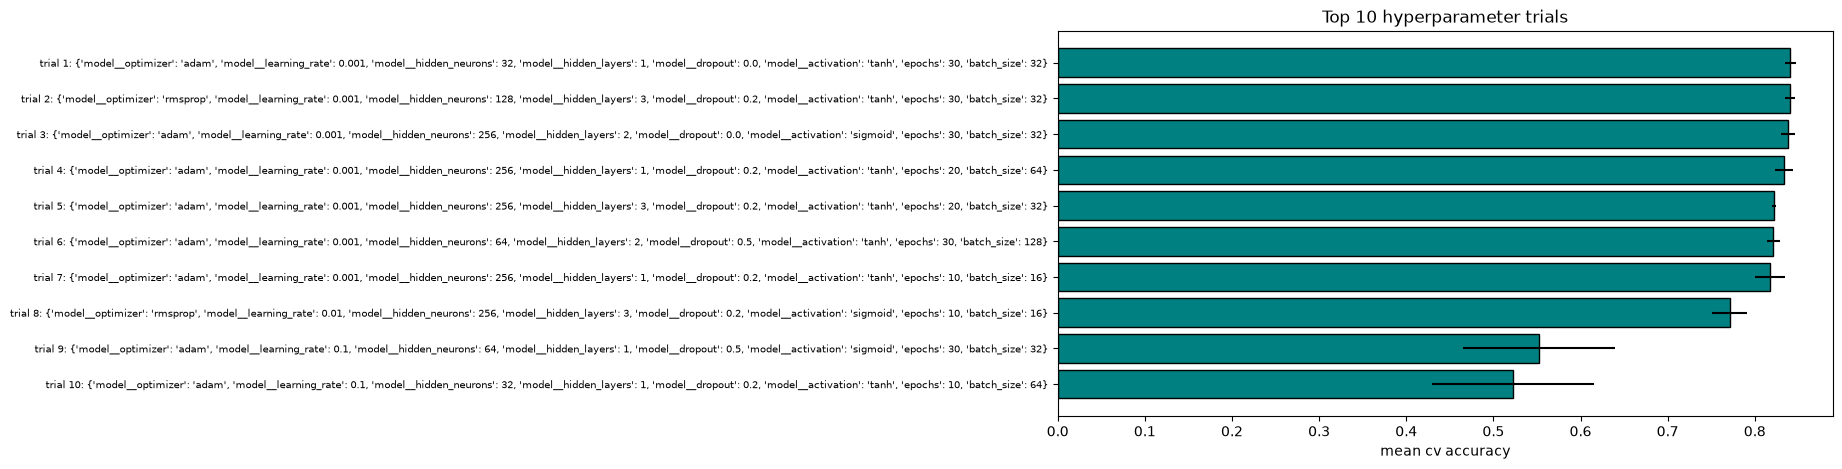

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(results_df)), results_df['mean_test_score'], xerr=results_df['std_test_score'], color='teal', edgecolor='black')
ax.set_yticks(range(len(results_df)))
labels = ["trial " + str(i + 1) + ": " + str(results_df['params'][i]) for i in range(len(results_df))]
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("mean cv accuracy")
ax.set_title("Top 10 hyperparameter trials")
plt.tight_layout()
plt.savefig("plot_08_hyperparameter_search.png", dpi=110, bbox_inches='tight')
plt.show()


In [15]:
best_params = dict(search_result.best_params_)
print("best params:", best_params)


best params: {'model__optimizer': 'adam', 'model__learning_rate': 0.001, 'model__hidden_neurons': 32, 'model__hidden_layers': 1, 'model__dropout': 0.0, 'model__activation': 'tanh', 'epochs': 30, 'batch_size': 32}


In [16]:
best_model = build_fn(
    hidden_layers=best_params['model__hidden_layers'],
    hidden_neurons=best_params['model__hidden_neurons'],
    learning_rate=best_params['model__learning_rate'],
    optimizer=best_params['model__optimizer'],
    activation=best_params['model__activation'],
    dropout=best_params['model__dropout']
)
best_model.summary()
t0 = time.time()
best_history = best_model.fit(
    x_train_flat, y_train_oh,
    validation_split=0.1,
    epochs=best_params['epochs'],
    batch_size=best_params['batch_size'],
    verbose=2
)
best_train_time = time.time() - t0
print("best model training time: %.2f s" % best_train_time)


Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_89 (Dense)                │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_90 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


... (56 outputs left out)

1688/1688 - 1s - 610us/step - accuracy: 0.9241 - loss: 0.2114 - val_accuracy: 0.8770 - val_loss: 0.3795


Epoch 30/30


1688/1688 - 1s - 613us/step - accuracy: 0.9250 - loss: 0.2090 - val_accuracy: 0.8770 - val_loss: 0.3831


best model training time: 31.80 s


In [17]:
best_acc, best_prec, best_rec, best_f1, y_pred_best = eval_model(best_model, "Optimized")


=== Optimized ===
accuracy : 0.8696
precision: 0.8689
recall   : 0.8696
f1       : 0.8684
              precision    recall  f1-score   support

     T-shirt     0.8117    0.8320    0.8217      1000
     Trouser     0.9748    0.9680    0.9714      1000
    Pullover     0.7960    0.7530    0.7739      1000
       Dress     0.8500    0.9070    0.8776      1000
        Coat     0.7635    0.8360    0.7981      1000
      Sandal     0.9348    0.9600    0.9472      1000
       Shirt     0.7224    0.6270    0.6713      1000
     Sneaker     0.9086    0.9540    0.9307      1000
         Bag     0.9602    0.9640    0.9621      1000
  Ankle boot     0.9676    0.8950    0.9299      1000

    accuracy                         0.8696     10000
   macro avg     0.8689    0.8696    0.8684     10000
weighted avg     0.8689    0.8696    0.8684     10000



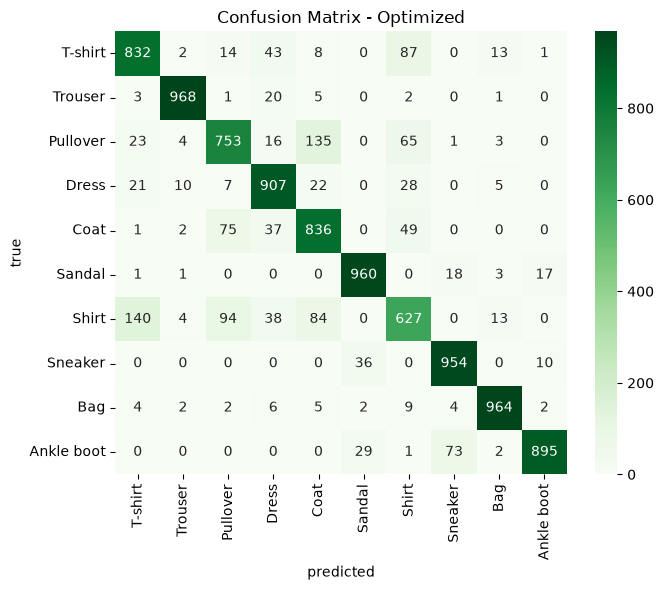

In [18]:
cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion Matrix - Optimized")
plt.tight_layout()
plt.savefig("plot_07_confusion_matrix_optimized.png", dpi=110, bbox_inches='tight')
plt.show()


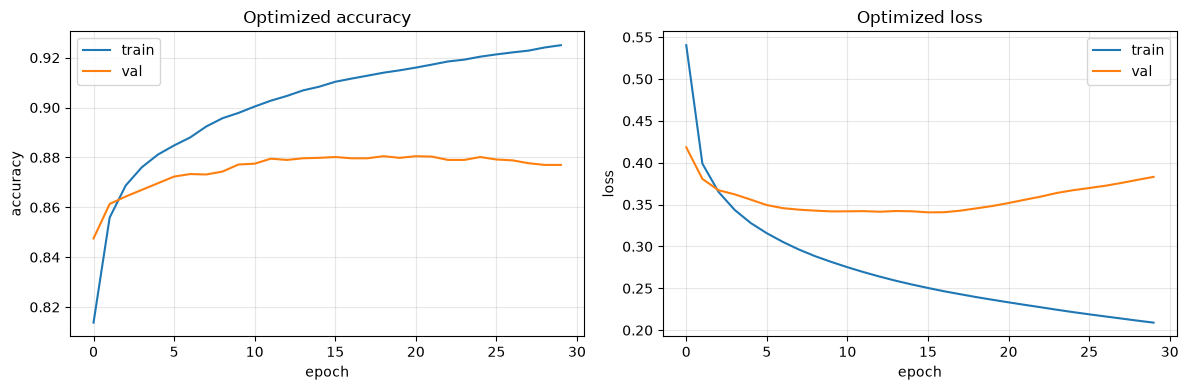

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(best_history.history['accuracy'], label='train')
axes[0].plot(best_history.history['val_accuracy'], label='val')
axes[0].set_title("Optimized accuracy")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(best_history.history['loss'], label='train')
axes[1].plot(best_history.history['val_loss'], label='val')
axes[1].set_title("Optimized loss")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot_03_04_05_06_optimized_curves.png", dpi=110, bbox_inches='tight')
plt.show()


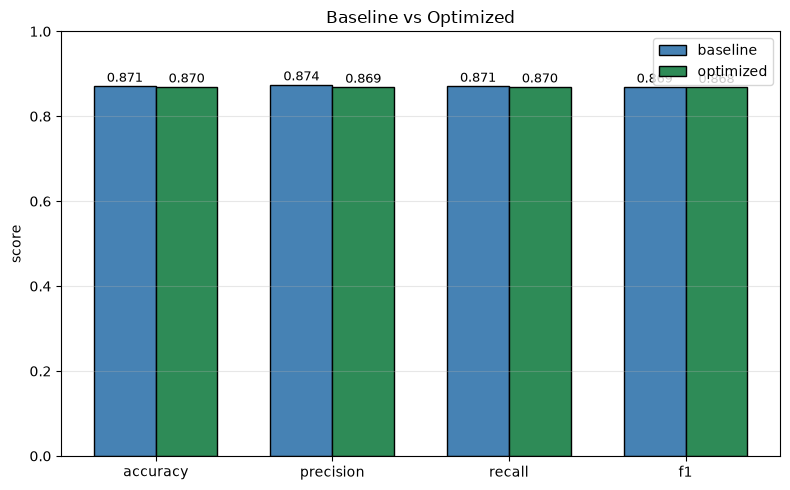

In [20]:
metrics_names = ['accuracy', 'precision', 'recall', 'f1']
baseline_vals = [baseline_acc, baseline_prec, baseline_rec, baseline_f1]
best_vals = [best_acc, best_prec, best_rec, best_f1]

xpos = np.arange(len(metrics_names))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(xpos - w / 2, baseline_vals, w, label='baseline', color='steelblue', edgecolor='black')
ax.bar(xpos + w / 2, best_vals, w, label='optimized', color='seagreen', edgecolor='black')
ax.set_xticks(xpos)
ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 1)
ax.set_ylabel("score")
ax.set_title("Baseline vs Optimized")
for i, (b, o) in enumerate(zip(baseline_vals, best_vals)):
    ax.text(i - w / 2, b + 0.01, "%.3f" % b, ha='center', fontsize=9)
    ax.text(i + w / 2, o + 0.01, "%.3f" % o, ha='center', fontsize=9)
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig("plot_09_comparison.png", dpi=110, bbox_inches='tight')
plt.show()
